# Linear discriminant analysis applied to breast cancer diagnosis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.stats import gaussian_kde
from matplotlib.lines import Line2D
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import confusion_matrix
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

Example taken from Izenman, A.J. (2008) Modern Multivariate Statistical Techniques. Springer.

The Wisconsin diagnostic breast cancer data have 30 measurements of the cell nuclei of 569 tumors, each tumor is malignant (`y = 0`) or benign (`y = 1`).

In [2]:
dat = load_breast_cancer(as_frame=True)

X = dat.data
y = dat.target.to_numpy()
features = X.columns
n, p = X.shape

classes = ['Malignant', 'Benign']
class_colors = ['#0072B2', '#E69F00']

pd.Series(y).map({0: 'Malignant', 1: 'Benign'}).value_counts()

Benign       357
Malignant    212
Name: count, dtype: int64

The variables have very different scales, and the matrix is badly conditioned. Following Izenman, we work with the logarithm of the variables (the zeros are replaced by 0.001).

In [3]:
print(f'Condition number: {np.linalg.cond(X):.1f}')

Condition number: 1485362.3


In [4]:
X = np.log(X.mask(X == 0).fillna(0.001)).to_numpy()

print(f'Condition number: {np.linalg.cond(X):.1f}')

Condition number: 6700.6


## Linear discriminant analysis by hand

Assuming that both classes are Gaussian with the same covariance matrix, we classify as benign when
$$L(x) = b_0 + b^Tx > 0, \qquad b = S^{-1}(\bar x_B - \bar x_M), \qquad b_0 = \log\frac{\pi_B}{\pi_M} - \frac{1}{2}(\bar x_B + \bar x_M)^Tb,$$
where $S$ is the pooled covariance matrix and $\pi_M$, $\pi_B$ are the proportions of each class.

In [5]:
def lda_fit(X, y):
    X_M, X_B = X[y == 0], X[y == 1]
    n_M, n_B = len(X_M), len(X_B)
    mean_M, mean_B = X_M.mean(axis=0), X_B.mean(axis=0)

    # Pooled covariance matrix
    S_M = np.atleast_2d(np.cov(X_M, rowvar=False))
    S_B = np.atleast_2d(np.cov(X_B, rowvar=False))
    S = ((n_M-1)*S_M + (n_B-1)*S_B)/(n_M+n_B-2)

    # Discriminant function (coefficients)
    b = np.linalg.solve(S, mean_B-mean_M)
    b0 = np.log(n_B/n_M) - (mean_B+mean_M) @ b / 2
    return b0, b

In [6]:
b0, b = lda_fit(X, y)
scores = b0 + X @ b
y_hat = (scores > 0).astype(int)

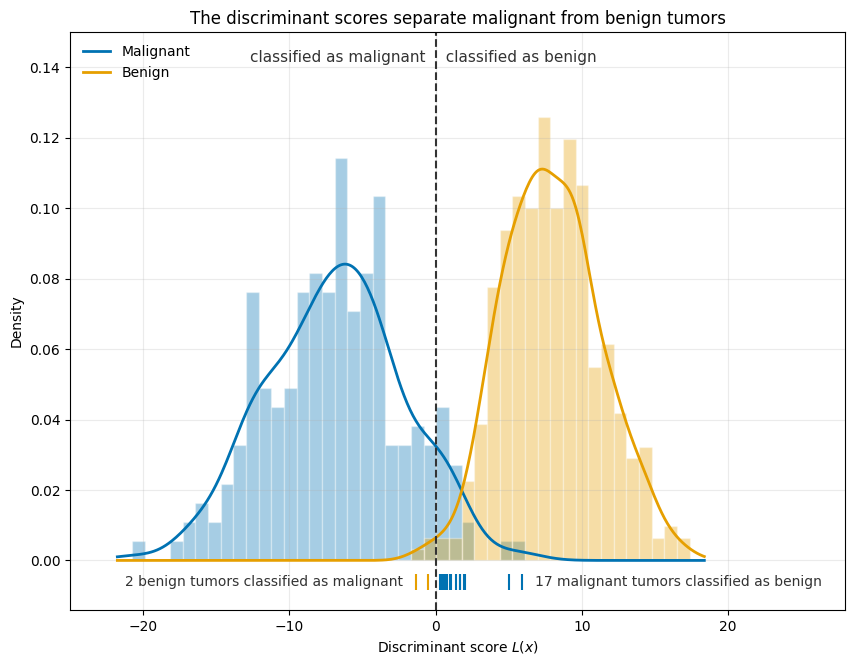

In [7]:
fig, ax = plt.subplots(figsize=(10, 7.5))
s_grid = np.linspace(scores.min()-1, scores.max()+1, 400)
bins = np.linspace(scores.min(), scores.max(), 45)

for k in [0, 1]:
    ax.hist(scores[y == k], bins=bins, density=True, color=class_colors[k], alpha=0.35,
            edgecolor='white', linewidth=1)
    ax.plot(s_grid, gaussian_kde(scores[y == k])(s_grid), color=class_colors[k], lw=2, label=classes[k])
    # Misclassified tumors as a rug: they are on the wrong side of the threshold
    wrong = scores[(y == k) & (y_hat != k)]
    ax.plot(wrong, np.full(len(wrong), -0.006), '|', color=class_colors[k], markersize=12, markeredgewidth=1.5)

ax.set_ylim(-0.014, 0.15)
ax.set_xlim(-25, 28)
ax.axvline(0, ls='--', color='#333333', lw=1.5)
ax.annotate('classified as malignant  ', (0, 0.145), ha='right', va='top', fontsize=11, color='#333333')
ax.annotate('  classified as benign', (0, 0.145), ha='left', va='top', fontsize=11, color='#333333')
ax.annotate(f'{((y == 0) & (y_hat == 1)).sum()} malignant tumors classified as benign', (6.8, -0.006),
            va='center', fontsize=10, color='#333333')
ax.annotate(f'{((y == 1) & (y_hat == 0)).sum()} benign tumors classified as malignant', (-2.2, -0.006),
            ha='right', va='center', fontsize=10, color='#333333')

ax.set_xlabel('Discriminant score $L(x)$')
ax.set_ylabel('Density')
ax.set_title('The discriminant scores separate malignant from benign tumors')
ax.legend(loc='upper left', frameon=False)
ax.grid(True, alpha=0.25)

## How good is the classifier?

Percentage of tumors wrongly classified, using the same data for fitting and for evaluating (apparent error).

In [8]:
conf_matrix = confusion_matrix(y, y_hat)
apparent_error = 100*(1-np.trace(conf_matrix)/n)
print(f'Apparent error: {apparent_error:.2f}%')

Apparent error: 3.34%


The apparent error is optimistic. Leave-one-out cross-validation gives a more realistic estimation: each tumor is classified with the rule fitted without it. We do it by hand and with `LinearDiscriminantAnalysis` from `sklearn`.

In [9]:
y_hat_cv = np.zeros(n, dtype=int)
y_hat_cv_sklearn = np.zeros(n, dtype=int)

for i in range(n):
    keep = np.arange(n) != i

    b0_i, b_i = lda_fit(X[keep], y[keep])
    y_hat_cv[i] = int(b0_i + X[i] @ b_i > 0)

    lda = LinearDiscriminantAnalysis()
    lda.fit(X[keep], y[keep])
    y_hat_cv_sklearn[i] = lda.predict(X[[i]])[0]

In [10]:
conf_matrix_cv = confusion_matrix(y, y_hat_cv)
cv_error = 100*(1-np.trace(conf_matrix_cv)/n)
print(f'Leave-one-out error (by hand): {cv_error:.2f}%')

Leave-one-out error (by hand): 4.22%


In [11]:
conf_matrix_cv_sklearn = confusion_matrix(y, y_hat_cv_sklearn)
print(f'Leave-one-out error (sklearn): {100*(1-np.trace(conf_matrix_cv_sklearn)/n):.2f}%')

Leave-one-out error (sklearn): 4.22%


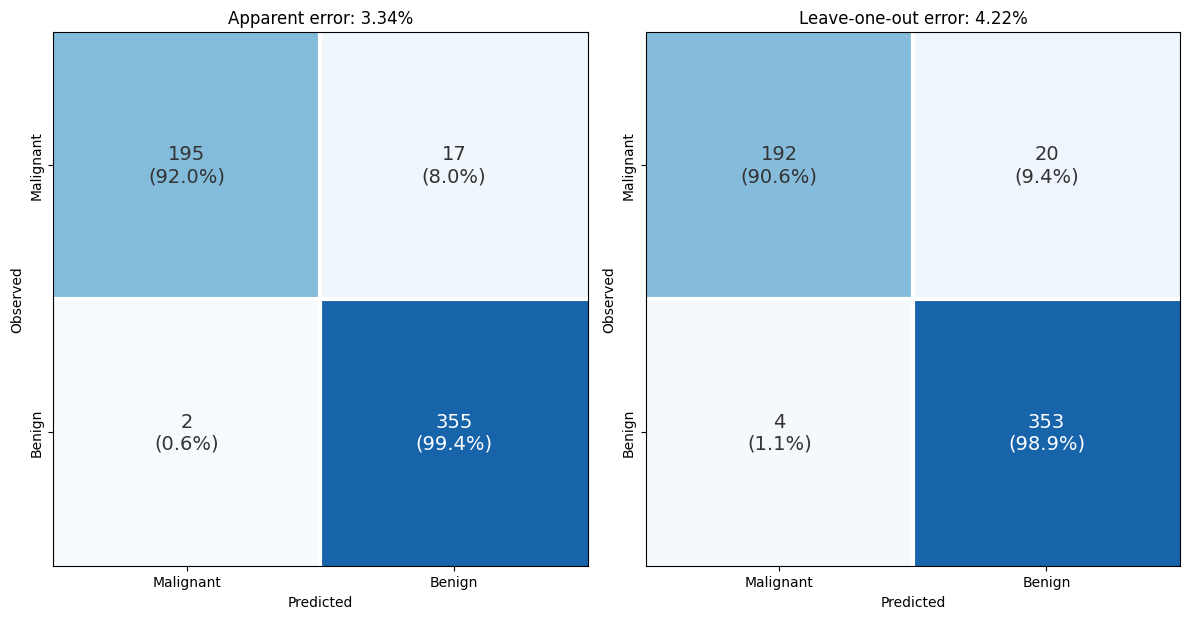

In [12]:
def plot_confusion_matrix(ax, conf_matrix, title):
    ax.imshow(conf_matrix, cmap='Blues', vmin=0, vmax=conf_matrix.max()*1.25)
    for i in range(2):
        for j in range(2):
            share = 100*conf_matrix[i, j]/conf_matrix[i].sum()
            ax.text(j, i, f'{conf_matrix[i, j]}\n({share:.1f}%)', ha='center', va='center', fontsize=14,
                    color='white' if conf_matrix[i, j] > 0.6*conf_matrix.max() else '#333333')
    ax.axhline(0.5, color='white', lw=3)
    ax.axvline(0.5, color='white', lw=3)
    ax.set_xticks([0, 1], classes)
    ax.set_yticks([0, 1], classes, rotation=90, va='center')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Observed')
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
plot_confusion_matrix(axes[0], conf_matrix, f'Apparent error: {apparent_error:.2f}%')
plot_confusion_matrix(axes[1], conf_matrix_cv, f'Leave-one-out error: {cv_error:.2f}%')
plt.tight_layout()

## Using LinearDiscriminantAnalysis

`sklearn` gives the same discriminant function.

In [13]:
lda = LinearDiscriminantAnalysis()
lda.fit(X, y)

print('Largest difference in the coefficients:', np.max(np.abs(lda.coef_[0] - b)))
print('Difference in the intercept:           ', np.abs(lda.intercept_[0] - b0))

Largest difference in the coefficients: 8.175504717655713e-11
Difference in the intercept:            5.5649707064731047e-11


## The decision boundary with two variables

With 30 variables we cannot draw the classifier. To see what it does, we look for the pair of variables with the smallest apparent error and fit the discriminant function with only those two: the boundary $L(x) = 0$ is a straight line.

In [14]:
errors = {}
for j, k in combinations(range(p), 2):
    b0_jk, b_jk = lda_fit(X[:, [j, k]], y)
    errors[(j, k)] = 100*np.mean((b0_jk + X[:, [j, k]] @ b_jk > 0) != y)

(j, k) = min(errors, key=errors.get)
print(f'Best pair: {features[j]} and {features[k]}, apparent error {errors[(j, k)]:.2f}%')

Best pair: worst perimeter and worst smoothness, apparent error 4.22%


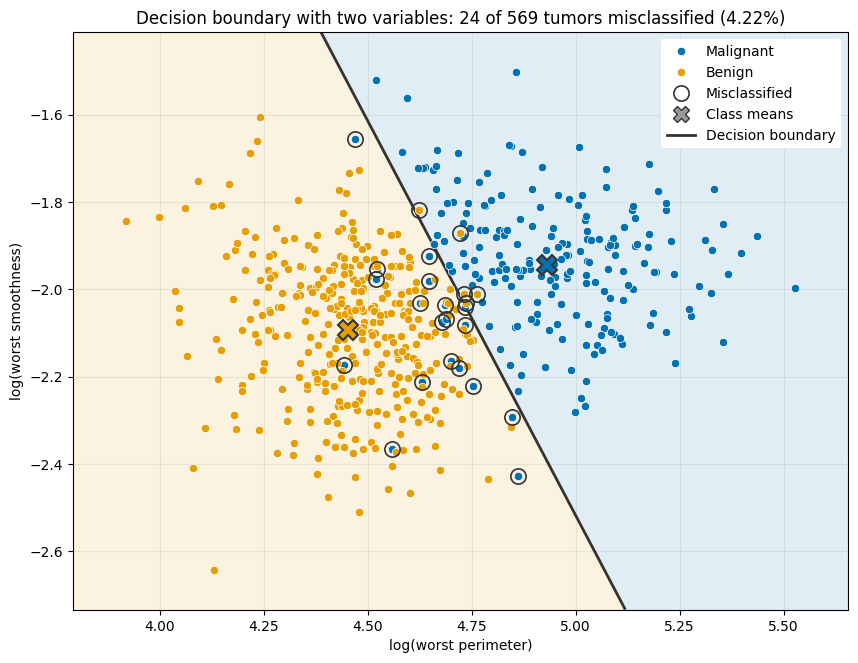

In [15]:
X_2 = X[:, [j, k]]
b0_2, b_2 = lda_fit(X_2, y)
y_hat_2 = (b0_2 + X_2 @ b_2 > 0).astype(int)

margin = 0.08*(X_2.max(axis=0) - X_2.min(axis=0))
grid_1 = np.linspace(X_2[:, 0].min()-margin[0], X_2[:, 0].max()+margin[0], 300)
grid_2 = np.linspace(X_2[:, 1].min()-margin[1], X_2[:, 1].max()+margin[1], 300)
G_1, G_2 = np.meshgrid(grid_1, grid_2)
L = b0_2 + b_2[0]*G_1 + b_2[1]*G_2

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.contourf(G_1, G_2, L, levels=[L.min(), 0, L.max()], colors=class_colors, alpha=0.12)
ax.contour(G_1, G_2, L, levels=[0], colors='#333333', linewidths=2)

for c in [0, 1]:
    ax.plot(X_2[y == c, 0], X_2[y == c, 1], 'o', color=class_colors[c], markersize=6,
            markeredgecolor='white', markeredgewidth=0.5, label=classes[c])
wrong = y_hat_2 != y
ax.plot(X_2[wrong, 0], X_2[wrong, 1], 'o', markersize=11, markerfacecolor='none',
        markeredgecolor='#333333', markeredgewidth=1.2, label='Misclassified')
for c in [0, 1]:
    ax.plot(*X_2[y == c].mean(axis=0), 'X', color=class_colors[c], markersize=15,
            markeredgecolor='#333333', markeredgewidth=1.5)
handles, labels = ax.get_legend_handles_labels()
handles += [Line2D([], [], marker='X', ls='', color='#999999', markersize=12, markeredgecolor='#333333'),
            Line2D([], [], color='#333333', lw=2)]
labels += ['Class means', 'Decision boundary']

ax.set_xlabel(f'log({features[j]})')
ax.set_ylabel(f'log({features[k]})')
ax.set_title(f'Decision boundary with two variables: {wrong.sum()} of {n} tumors misclassified ({100*wrong.mean():.2f}%)')
ax.legend(handles, labels, loc='best', framealpha=1, edgecolor='none')
ax.grid(True, alpha=0.25)